In [2]:
import pandas as pd

songs = pd.read_csv("songs_normalize.csv")

print("Dataset shape:", songs.shape)
print("\nColumns:", songs.columns.tolist())

songs.head()


Dataset shape: (2000, 18)

Columns: ['artist', 'song', 'duration_ms', 'explicit', 'year', 'popularity', 'danceability', 'energy', 'key', 'loudness', 'mode', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'genre']


,artist,song,duration_ms,explicit,year,popularity,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,genre
0,Britney Spears,Oops!...I Did It Again,211160,False,2000,77,0.751,0.834,1,-5.444,0,0.0437,0.3000,0.000018,0.3550,0.894,95.053,pop
1,blink-182,All The Small Things,167066,False,1999,79,0.434,0.897,0,-4.918,1,0.0488,0.0103,0.000000,0.6120,0.684,148.726,"rock, pop"
2,Faith Hill,Breathe,250546,False,1999,66,0.529,0.496,7,-9.007,1,0.0290,0.1730,0.000000,0.2510,0.278,136.859,"pop, country"
3,Bon Jovi,It's My Life,224493,False,2000,78,0.551,0.913,0,-4.063,0,0.0466,0.0263,0.000013,0.3470,0.544,119.992,"rock, metal"
4,*NSYNC,Bye Bye Bye,200560,False,2000,65,0.614,0.928,8,-4.806,0,0.0516,0.0408,0.001040,0.0845,0.879,172.656,pop


In [3]:
print("Earliest year:", songs["year"].min())
print("Latest year:", songs["year"].max())

print("\nMissing values:")
print(songs.isnull().sum())

print("\nDuplicate rows:", songs.duplicated().sum())

songs[["danceability", "energy", "valence"]].describe()


Earliest year: 1998
Latest year: 2020

Missing values:
artist              0
song                0
duration_ms         0
explicit            0
year                0
popularity          0
danceability        0
energy              0
key                 0
loudness            0
mode                0
speechiness         0
acousticness        0
instrumentalness    0
liveness            0
valence             0
tempo               0
genre               0
dtype: int64

Duplicate rows: 59


,danceability,energy,valence
count,2000.000000,2000.000000,2000.000000
mean,0.667438,0.720366,0.551690
std,0.140416,0.152745,0.220864
min,0.129000,0.054900,0.038100
25%,0.581000,0.622000,0.386750
50%,0.676000,0.736000,0.557500
75%,0.764000,0.839000,0.730000
max,0.975000,0.999000,0.973000


In [4]:
songs = songs.drop_duplicates().copy()

print("Songs after cleaning:", len(songs))

features = ["danceability", "energy", "valence"]

X = songs[features]

X.head()


Songs after cleaning: 1941


,danceability,energy,valence
0,0.751,0.834,0.894
1,0.434,0.897,0.684
2,0.529,0.496,0.278
3,0.551,0.913,0.544
4,0.614,0.928,0.879


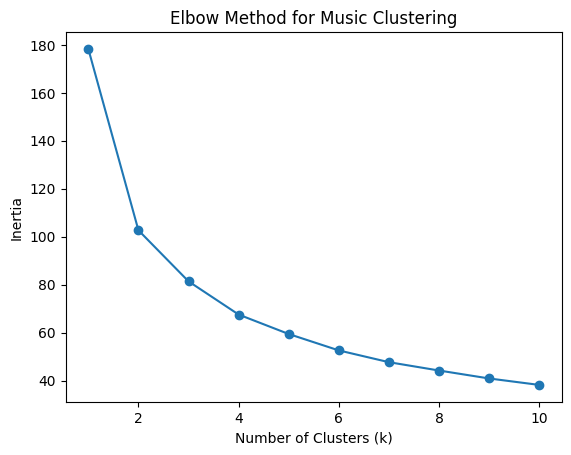

In [5]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

# Test different numbers of clusters
inertias = []

for k in range(1, 11):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X)
    inertias.append(model.inertia_)

# Plot the elbow graph
plt.plot(range(1, 11), inertias, marker="o")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia")
plt.title("Elbow Method for Music Clustering")
plt.show()


In [6]:
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)

songs["cluster"] = kmeans.fit_predict(X)

print("Songs in each cluster:")
print(songs["cluster"].value_counts().sort_index())

print("\nAverage features by cluster:")
print(songs.groupby("cluster")[features].mean().round(3))


Songs in each cluster:
cluster
0    508
1    657
2    430
3    346
Name: count, dtype: int64

Average features by cluster:
         danceability  energy  valence
cluster                               
0               0.562   0.830    0.481
1               0.737   0.790    0.789
2               0.756   0.599    0.531
3               0.582   0.584    0.237


In [9]:
for cluster in range(4):
    print("\nCluster", cluster)

    examples = songs[songs["cluster"] == cluster]

    print(examples[["artist", "song", "danceability", "energy", "valence"]].head(5).to_string(index=False))



Cluster 0
     artist                 song  danceability  energy  valence
  blink-182 All The Small Things         0.434   0.897    0.684
   Bon Jovi         It's My Life         0.551   0.913    0.544
    Dr. Dre     The Next Episode         0.922   0.909    0.309
Linkin Park           In the End         0.556   0.864    0.400
Limp Bizkit   Take A Look Around         0.425   0.852    0.512

Cluster 1
         artist                   song  danceability  energy  valence
 Britney Spears Oops!...I Did It Again         0.751   0.834    0.894
         *NSYNC            Bye Bye Bye         0.614   0.928    0.879
          Sisqo             Thong Song         0.706   0.888    0.714
         Eminem    The Real Slim Shady         0.949   0.661    0.760
Robbie Williams                Rock DJ         0.708   0.772    0.861

Cluster 2
       artist                    song  danceability  energy  valence
    Melanie C Never Be The Same Again         0.689   0.685    0.398
      Sonique        It F

In [10]:
print("Songs analyzed:", len(songs))
print("Songs assigned to clusters:", songs["cluster"].count())

print("Number of clusters:", songs["cluster"].nunique())

print("Missing cluster assignments:", songs["cluster"].isnull().sum())

print("Total songs across clusters:", songs["cluster"].value_counts().sum())


Songs analyzed: 1941
Songs assigned to clusters: 1941
Number of clusters: 4
Missing cluster assignments: 0
Total songs across clusters: 1941


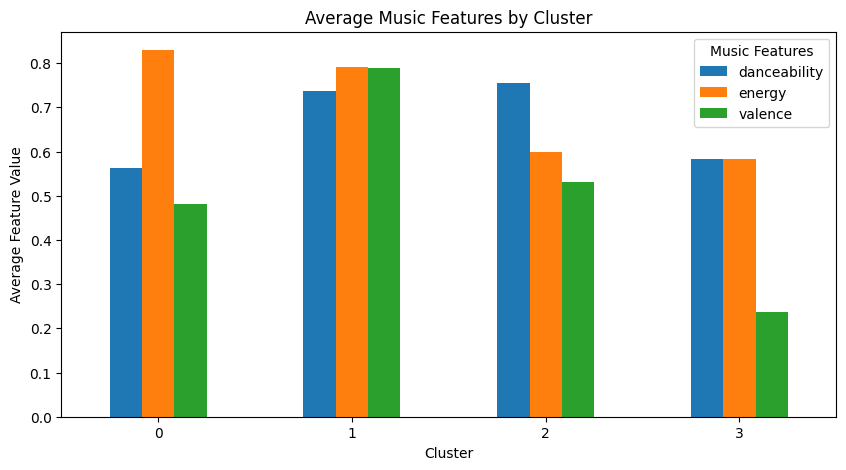

In [11]:

cluster_averages = songs.groupby("cluster")[features].mean()

cluster_averages.plot(kind="bar", figsize=(10, 5))

plt.title("Average Music Features by Cluster")
plt.xlabel("Cluster")
plt.ylabel("Average Feature Value")
plt.xticks(rotation=0)
plt.legend(title="Music Features")
plt.show()
